# bangla-qwen-pro — QLoRA fine-tune of Qwen3.5-0.8B for Bangla

**Google Colab, free T4.** `Runtime` → `Change runtime type` → **T4 GPU**, then `Run all`.
Put your Hugging Face **write** token in Colab Secrets as `HF_TOKEN` (key icon, left
sidebar, toggle "Notebook access" on). Roughly 2 hours.

The companion to `bangla-gemma-pro`: **same seven datasets, same evaluation harness, same
card structure**, so the two sets of numbers sit side by side honestly. What differs is
the base model and the method.

| | bangla-gemma-pro | this notebook |
|---|---|---|
| Base | Gemma-3-1B (140+ languages) | **Qwen3.5-0.8B (201 languages)** |
| Method | full fine-tune | **QLoRA, 4-bit NF4** |
| Hardware | Kaggle T4 | Colab free T4 |

### Two things about Qwen3.5 that shape this notebook

**It is multimodal.** Hugging Face lists it as `image-text-to-text` and the architecture is
`qwen3_5_text`. Only the text tower is trained here; the vision modules are left alone.

**Qwen3-family models have a thinking mode.** The chat template can emit reasoning blocks,
which would poison supervised fine-tuning on plain instruction data. Section 3 turns it off
and prints the rendered template so you can see what the model is actually trained on.

### Why Qwen3.5 for Bangla

201 languages against Gemma-3's 140, and a 248k vocabulary. Section 4 measures tokens per
Bangla word for both, which is the number that decides context cost.

## 1. Environment

In [1]:
import subprocess, os, shutil
try:
    print(subprocess.check_output(["nvidia-smi","--query-gpu=name,memory.total",
                                   "--format=csv,noheader"]).decode().strip())
except Exception:
    print("No GPU — Runtime > Change runtime type > T4 GPU")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
print("disk free in /content:", round(shutil.disk_usage("/content").free/1e9, 1), "GB")

Tesla T4, 15360 MiB
disk free in /content: 75.5 GB


In [2]:
!pip install -q unsloth
!pip install -q --no-deps --upgrade git+https://github.com/unslothai/unsloth.git
!pip install -q sacrebleu matplotlib
print("installed")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.4/30.4 MB 75.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 87.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 64.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 99.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 115.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 125.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 112.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 23.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting 

## 2. Configuration

**QLoRA on a free T4.** The base is stored in 4-bit NF4 with double quantisation while
gradients flow in fp16. At 0.8B this is not about making the model fit — it would fit in
fp16 — but about freeing memory for a 1024-token context at batch 4.

T4 is Turing, so there is **no bfloat16**: compute dtype is fp16 throughout, and
`max_grad_norm=0.3` guards against the overflow that fp16 training over a quantised base
invites.

In [ ]:
from google.colab import userdata
userdata.get('secretName')

In [5]:
import gc, re, json, time, random, inspect, math
import numpy as np
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from unsloth import FastModel, is_bfloat16_supported
from unsloth.chat_templates import train_on_responses_only
from datasets import load_dataset
from trl import SFTTrainer

BASE_MODEL  = "unsloth/Qwen3.5-0.8B"           # Unsloth's pre-patched mirror
UPSTREAM    = "Qwen/Qwen3.5-0.8B"
SFT_DATASET = "md-nishat-008/Bangla-Instruct"  # 100K native Bangla instructions
PPL_DATASET = "csebuetnlp/xlsum"               # held-out Bangla prose for perplexity

MAX_SEQ   = 512
BATCH     = 4                                  # 0.8B in 4-bit leaves plenty of room
ACCUM     = 4                                  # effective 16
MAX_STEPS = 400
LR        = 2e-4                               # QLoRA range, ten times a full fine-tune's
LORA_R    = 32                                 # small model, so more adapter capacity
LORA_ALPHA = 64
SEED      = 3407

BENCH_N   = 300                                # per benchmark
PPL_N     = 200
MODEL_NAME = "bangla-gpt-pro"

WORK   = "/content"
SAVE   = f"{WORK}/{MODEL_NAME}"
MERGED = f"{WORK}/{MODEL_NAME}-merged"
GGUF   = f"{WORK}/{MODEL_NAME}-GGUF"
ASSETS = f"{SAVE}/assets"
for d in (SAVE, ASSETS):
    os.makedirs(d, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
GPU, BF16 = torch.cuda.get_device_name(0), is_bfloat16_supported()
print(f"{GPU} | bfloat16 {BF16} -> training in {'bf16' if BF16 else 'fp16'}")

plt.rcParams.update({"figure.dpi":130,"savefig.dpi":130,"savefig.bbox":"tight","font.size":10,
                     "axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.alpha":.25,"figure.facecolor":"white"})
C_BASE, C_TUNED = "#94a3b8", "#059669"

def vram(): return torch.cuda.max_memory_allocated()/1e9
def clear(): gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception as e:
    raise RuntimeError(
        "Add your Hugging Face write token to Colab Secrets as HF_TOKEN "
        "(key icon in the left sidebar, then enable Notebook access)."
    ) from e
os.environ["HF_TOKEN"] = HF_TOKEN
from huggingface_hub import login, create_repo, upload_folder, whoami
login(token=HF_TOKEN)
HF_USERNAME = whoami()["name"]
REPO_ID   = f"{HF_USERNAME}/{MODEL_NAME}"
GGUF_REPO = f"{HF_USERNAME}/{MODEL_NAME}-GGUF"
print(f"logged in as {HF_USERNAME} -> {REPO_ID}")

Tesla T4 | bfloat16 False -> training in fp16
logged in as emonHasan01 -> emonHasan01/bangla-gpt-pro


## 3. Load in 4-bit, and pin down the chat template

QLoRA: the base is stored in 4-bit NF4 with double quantisation, gradients still flow in
fp16. At 0.8B this is not about fitting — it fits easily either way — it is about leaving
headroom for a 1024-token context and batch 4 on a free T4.

The template handling below is defensive on purpose. Qwen3.5 is new, its turn markers are
not guaranteed to match earlier Qwen releases, and `train_on_responses_only` silently
supervises the wrong tokens if the markers are wrong. So they are **detected from the
rendered template**, not hard-coded.

In [6]:
clear()
model, tokenizer = FastModel.from_pretrained(
    model_name     = BASE_MODEL,
    max_seq_length = MAX_SEQ,
    dtype          = None,
    load_in_4bit   = True,          # QLoRA
    full_finetuning = False,
)
N_PARAMS = sum(p.numel() for p in model.parameters())
VRAM_4BIT = vram()
print(f"loaded | {VRAM_4BIT:.2f} GB VRAM in 4-bit")

SYSTEM_BN = "আপনি একজন সহায়ক সহকারী। সবসময় স্পষ্ট ও সঠিক বাংলায় উত্তর দিন।"

def _render(msgs, gen_prompt=False):
    """Apply the model's own template, with thinking mode off where supported."""
    for kwargs in ({"enable_thinking": False}, {"thinking": False}, {}):
        try:
            return tokenizer.apply_chat_template(
                msgs, tokenize=False, add_generation_prompt=gen_prompt, **kwargs)
        except TypeError:
            continue
    raise RuntimeError("could not render the chat template")

def to_chat(user, assistant=None, system=SYSTEM_BN):
    msgs = []
    if system:
        msgs.append({"role": "system", "content": system})
    msgs.append({"role": "user", "content": user})
    if assistant is not None:
        msgs.append({"role": "assistant", "content": assistant})
    return msgs

SAMPLE = _render(to_chat("USERMARK", "ASSISTANTMARK"))
print("--- rendered training template ---")
print(SAMPLE)

# Detect the turn markers rather than assuming Qwen's older <|im_start|> convention.
# The marker must include the role name: the special token alone is identical for both
# turns, and train_on_responses_only would then supervise the question.
ROLE_HDR = re.compile(r"(<\|[^|]*\|>|<start_of_turn>)\s*(user|assistant|model)\s*\n")

def find_markers(sample):
    found = {}
    for m in ROLE_HDR.finditer(sample):
        role = m.group(2)
        key = "assistant" if role in ("assistant", "model") else role
        found.setdefault(key, m.group(0))
    return found.get("user"), found.get("assistant")

INSTRUCTION_PART, RESPONSE_PART = find_markers(SAMPLE)
print(f"\ninstruction_part = {INSTRUCTION_PART!r}")
print(f"response_part    = {RESPONSE_PART!r}")
assert INSTRUCTION_PART and RESPONSE_PART and INSTRUCTION_PART != RESPONSE_PART, \
    ("Could not separate the user and assistant turn markers from the template above. "
     "Set INSTRUCTION_PART and RESPONSE_PART by hand from the printed template.")

THINKING_IN_TEMPLATE = "<think>" in SAMPLE or "thinking" in SAMPLE.lower()
print("thinking block present in rendered template:", THINKING_IN_TEMPLATE)
if THINKING_IN_TEMPLATE:
    print("  NOTE: training data has no reasoning traces, so this would teach the model to "
          "emit empty think blocks. Check the rendered template above before continuing.")

==((====))==  Unsloth 2026.10.6: Fast Qwen3_5 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

loaded | 1.49 GB VRAM in 4-bit
--- rendered training template ---
<|im_start|>system
আপনি একজন সহায়ক সহকারী। সবসময় স্পষ্ট ও সঠিক বাংলায় উত্তর দিন।<|im_end|>
<|im_start|>user
USERMARK<|im_end|>
<|im_start|>assistant
<think>

</think>

ASSISTANTMARK<|im_end|>


instruction_part = '<|im_start|>user\n'
response_part    = '<|im_start|>assistant\n'
thinking block present in rendered template: True
  NOTE: training data has no reasoning traces, so this would teach the model to emit empty think blocks. Check the rendered template above before continuing.


In [7]:
# Qwen3.5 is multimodal, so Unsloth may hand back a processor rather than a tokenizer.
# Everything below needs the plain text tokenizer.
if hasattr(tokenizer, "tokenizer"):
    processor = tokenizer
    tokenizer = processor.tokenizer
    print("unwrapped the processor ->", type(tokenizer).__name__)
else:
    processor = None
    print("already a plain tokenizer ->", type(tokenizer).__name__)

probe = tokenizer("বাংলা পরীক্ষা", add_special_tokens=False)["input_ids"]
assert isinstance(probe, list) and len(probe) > 0, "tokenizer still not behaving as text-only"
print("text tokenization works:", len(probe), "tokens")

unwrapped the processor -> Qwen2Tokenizer
text tokenization works: 10 tokens


## 4. Tokenizer efficiency on Bangla

A detail most Bangla model cards skip. Gemma-3 ships a 262k-token vocabulary covering
140+ languages, so Bangla should fragment less than it does under an English-centric
tokenizer. Worth measuring rather than assuming, because tokens per word sets both the
effective context length and the cost of every request.

In [8]:
BN_SAMPLES = [
    "বাংলাদেশের রাজধানী ঢাকা একটি জনবহুল শহর।",
    "বিজ্ঞান ও প্রযুক্তির অগ্রগতি আমাদের জীবনযাত্রাকে সহজ করেছে।",
    "তিনি প্রতিদিন সকালে নদীর ধারে হাঁটতে যেতেন এবং পাখির ডাক শুনতেন।",
    "অর্থনৈতিক উন্নয়নের জন্য শিক্ষার বিকল্প নেই।",
]
tok_counts, word_counts = [], []
for s in BN_SAMPLES:
    tok_counts.append(len(tokenizer(s, add_special_tokens=False)["input_ids"]))
    word_counts.append(len(s.split()))
TOKENS_PER_WORD = sum(tok_counts)/sum(word_counts)
print(f"Bangla: {sum(tok_counts)} tokens for {sum(word_counts)} words "
      f"-> {TOKENS_PER_WORD:.2f} tokens/word")
en = "The capital of Bangladesh, Dhaka, is a densely populated city."
en_tpw = len(tokenizer(en, add_special_tokens=False)["input_ids"])/len(en.split())
print(f"English comparison: {en_tpw:.2f} tokens/word")
print(f"Bangla costs {TOKENS_PER_WORD/en_tpw:.1f}x more tokens per word than English")

Bangla: 128 tokens for 31 words -> 4.13 tokens/word
English comparison: 1.40 tokens/word
Bangla costs 2.9x more tokens per word than English


## 5. Benchmark harness

Each dataset is shaped differently, so columns are detected rather than assumed, and the
detected mapping is printed so a wrong guess is visible immediately.

Scoring is length-normalised log-likelihood: the average log probability of each option's
tokens given the question. Length normalisation matters because without it the model
simply prefers whichever option is shortest.

In [9]:
BENCHMARKS = [
    ("bangla-mmlu",      "hishab/bangla-mmlu"),
    ("commonsenseqa-bn", "hishab/commonsenseqa-bn"),
    ("openbookqa-bn",    "hishab/openbookqa-bn"),
    ("piqa-bn",          "hishab/piqa-bn"),
    ("boolq-bn",         "hishab/boolq_bn"),
]

Q_KEYS   = ["question","query","prompt","goal","ques","question_bn","instruction"]
CTX_KEYS = ["passage","context","paragraph","fact1","support"]
ANS_KEYS = ["answer","label","answerKey","correct","target","sol","answer_index"]

def find_options(row):
    """Return the option list however this dataset happens to store them."""
    for k in ["choices","options","endings","candidates"]:
        v = row.get(k)
        if isinstance(v, dict) and "text" in v:
            return list(v["text"])
        if isinstance(v, list) and len(v) >= 2:
            return [str(x) for x in v]
    lettered = [k for k in row if re.fullmatch(r"(option_?)?[A-Da-d1-4]", str(k))]
    if len(lettered) >= 2:
        return [str(row[k]) for k in sorted(lettered)]
    for pair in [("sol1","sol2"), ("answer1","answer2")]:
        if all(p in row for p in pair):
            return [str(row[p]) for p in pair]
    if isinstance(row.get("answer"), bool) or str(row.get("answer")).lower() in ("true","false"):
        return ["হ্যাঁ", "না"]
    return None

def gold_index(row, options):
    for k in ANS_KEYS:
        if k not in row:
            continue
        v = row[k]
        if isinstance(v, bool):
            return 0 if v else 1
        if isinstance(v, (int, np.integer)):
            return int(v) - 1 if int(v) == len(options) and len(options) < int(v)+1 else int(v)
        s = str(v).strip()
        if s.isdigit():
            i = int(s)
            return i if i < len(options) else i-1
        if len(s) == 1 and s.upper() in "ABCD":
            return "ABCD".index(s.upper())
        if s.lower() in ("true","yes","হ্যাঁ"):
            return 0
        if s.lower() in ("false","no","না"):
            return 1
        for i, o in enumerate(options):
            if s == str(o).strip():
                return i
    return None

def load_bench(name, repo, n=BENCH_N):
    try:
        ds = load_dataset(repo, split="test")
    except Exception:
        try:
            ds = load_dataset(repo, split="validation")
        except Exception as e:
            print(f"  {name}: could not load ({str(e)[:90]})")
            return None
    ds = ds.shuffle(seed=SEED)
    items, row0 = [], None
    for row in ds:
        opts = find_options(row)
        if not opts:
            continue
        gi = gold_index(row, opts)
        if gi is None or not (0 <= gi < len(opts)):
            continue
        q = next((str(row[k]) for k in Q_KEYS if row.get(k)), None)
        if not q:
            continue
        ctx = next((str(row[k]) for k in CTX_KEYS if row.get(k)), "")
        items.append({"q": q, "ctx": ctx, "options": opts, "gold": gi})
        row0 = row0 or row
        if len(items) >= n:
            break
    if not items:
        print(f"  {name}: no usable rows; columns were {list(ds.column_names)}")
        return None
    print(f"  {name}: {len(items)} items, {len(items[0]['options'])} options, "
          f"columns {list(ds.column_names)[:6]}")
    return items

print("loading benchmarks")
BENCH = {}
for name, repo in BENCHMARKS:
    it = load_bench(name, repo)
    if it:
        BENCH[name] = it
assert BENCH, "No benchmark loaded — check Internet is enabled in Kaggle settings."
print(f"\n{len(BENCH)} benchmarks ready: {list(BENCH)}")
print("\nexample item:", json.dumps(BENCH[list(BENCH)[0]][0], ensure_ascii=False)[:400])

loading benchmarks


README.md:   0%|          | 0.00/2.26k [00:00<?, ?B/s]

data/dev-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 33.6kB            

data/dev-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.52MB            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/815 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/432 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/729 [00:00<?, ? examples/s]

  boolq-bn: no usable rows; columns were ['passage', 'question', 'answer', 'answer_bn']

2 benchmarks ready: ['bangla-mmlu', 'piqa-bn']

example item: {"q": "কেঁচোর সিলোমে এক ধরনের সাদা তরল থাকে। সেখানে ভাসমান যে কণিকা পাওয়া যায় না সেটা হচ্ছে-", "ctx": "", "options": ["ক্লোরোগোজেন কোষ", "গোলাকার কোষ", "মিউকোসাইট", "স্তম্ভাকার কোষ"], "gold": 3}


In [10]:
@torch.no_grad()
def option_logprob(prompt_ids, option_text):
    opt_ids = tokenizer(option_text, add_special_tokens=False)["input_ids"]
    if not opt_ids:
        return -1e9
    ids = torch.tensor([prompt_ids + opt_ids], device="cuda")
    labels = ids.clone()
    labels[:, :len(prompt_ids)] = -100          # score the option only
    out = model(input_ids=ids, labels=labels)
    return -float(out.loss)                     # mean log prob per option token

@torch.no_grad()
def run_benchmarks(tag):
    model.eval()
    results = {}
    for name, items in BENCH.items():
        t0, correct = time.time(), 0
        for it in items:
            user = (f"{it['ctx']}\n\n{it['q']}" if it["ctx"] else it["q"])
            prompt = _render(to_chat(user), gen_prompt=True)
            pids = tokenizer(prompt, add_special_tokens=False)["input_ids"][-(MAX_SEQ-64):]
            scores = [option_logprob(pids, o) for o in it["options"]]
            correct += int(int(np.argmax(scores)) == it["gold"])
        acc = correct/len(items)
        results[name] = round(acc, 4)
        print(f"  {tag} {name:18} {acc:.3f}  ({time.time()-t0:.0f}s)")
    results["average"] = round(float(np.mean([v for k, v in results.items()
                                              if k != "average"])), 4)
    print(f"  {tag} {'AVERAGE':18} {results['average']:.3f}")
    return results

@torch.no_grad()
def perplexity(texts):
    model.eval()
    nll, ntok = 0.0, 0
    for t in texts:
        ids = tokenizer(t, add_special_tokens=False, truncation=True,
                        max_length=MAX_SEQ)["input_ids"]
        if len(ids) < 16:
            continue
        x = torch.tensor([ids], device="cuda")
        loss = model(input_ids=x, labels=x).loss
        nll += float(loss)*(len(ids)-1); ntok += len(ids)-1
    return round(math.exp(nll/max(ntok,1)), 2)

try:
    ppl_ds = load_dataset(PPL_DATASET, "bengali", split="test").shuffle(seed=SEED)
    PPL_TEXTS = [r["text"] for r in ppl_ds.select(range(PPL_N))]
    print(f"\nperplexity corpus: {len(PPL_TEXTS)} Bangla documents")
except Exception as e:
    print("\nperplexity corpus unavailable:", str(e)[:120])
    PPL_TEXTS = []

README.md:   0%|          | 0.00/14.6k [00:00<?, ?B/s]

xlsum.py:   0%|          | 0.00/4.55k [00:00<?, ?B/s]


perplexity corpus unavailable: Dataset scripts are no longer supported, but found xlsum.py


## 6. Baseline

The number everything else is judged against. Gemma-3-1B-it is already multilingual, so
the question is not whether it can read Bangla but whether this fine-tune improves it.

In [11]:
clear()
print("baseline:")
BASE_BENCH = run_benchmarks("base")
BASE_PPL = perplexity(PPL_TEXTS) if PPL_TEXTS else None
print("baseline perplexity:", BASE_PPL)

PROBES = [
    "বাংলাদেশের মুক্তিযুদ্ধ সম্পর্কে তিনটি বাক্যে লিখুন।",
    "রবীন্দ্রনাথ ঠাকুর কে ছিলেন?",
    "একটি ছোট গল্প লিখুন যেখানে একজন কৃষক বৃষ্টির জন্য অপেক্ষা করছেন।",
    "পানি ফুটলে কী ঘটে, সহজ ভাষায় ব্যাখ্যা করুন।",
]

@torch.no_grad()
def generate(texts, max_new=200):
    model.eval()
    outs = []
    for t in texts:
        p = _render(to_chat(t), gen_prompt=True)
        enc = tokenizer(p, return_tensors="pt", add_special_tokens=False).to("cuda")
        g = model.generate(**enc, max_new_tokens=max_new, do_sample=False, use_cache=True)
        outs.append(tokenizer.decode(g[0][enc["input_ids"].shape[1]:],
                                     skip_special_tokens=True).strip())
    return outs

BASE_GEN = generate(PROBES)
for q, a in zip(PROBES, BASE_GEN):
    print(f"\nপ্রশ্ন: {q}\nবেস: {a[:260]}")
clear()

baseline:


`causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


  base bangla-mmlu        0.283  (262s)
  base piqa-bn            0.500  (71s)
  base AVERAGE            0.392
baseline perplexity: None


`causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.



প্রশ্ন: বাংলাদেশের মুক্তিযুদ্ধ সম্পর্কে তিনটি বাক্যে লিখুন।
বেস: আমি আপনার সাহায্য করতে পারি। তবে, আপনি জানেন কি আপনি কোনো নির্দিষ্ট বিষয়টি (যেমন: বানানো, লিখা, বা অন্য কোনো বিষয়) সম্পর্কে স্পষ্টভাবে জানেন?

আমি আপনার সাহায্য করতে পারি:
*   **বানানো ও লিখা:** সঠিক বানানো এবং সঠিক লিখণ্ডন।
*   **ব্যাখ্যা ও ব্যাখ্য:** ব্যাখ

প্রশ্ন: রবীন্দ্রনাথ ঠাকুর কে ছিলেন?
বেস: আমি একটি সহকারী হিসেবে আপনার প্রশ্নের উত্তরটি নিচে দেওয়া হলো:

**রবীন্দ্রনাম ঠাকুরের ছিলেন ছিল ১৯৯০ সালে।**

এটি একটি গুরুত্বপূর্ণ ঘটনা। ১৯৯০ সালের ১৫ জুন, রবীন্দ্রনাম ঠাকুরের মৃত্যু ঘটে। তার মৃত্যের পরেই তিনি তার ছিলেনের জন্য আশ্রয় নিয়েছিলেন। এই ছিলেনের সম

প্রশ্ন: একটি ছোট গল্প লিখুন যেখানে একজন কৃষক বৃষ্টির জন্য অপেক্ষা করছেন।
বেস: আমি আপনার জন্য একটি ছোট গল্প লিখছি। এটি একটি কৃষিকর্মী হিসেবে কাজ করছেন একজন বৃহ্টির জন্য।

**গল্প: বৃহ্টির জন্যের ঘর**

আমি একজন বৃহ্টির জন্য। আমার ঘরটি খুবই বড় এবং সুন্দর। ঘরটিতে সবসময়ই কৃষিকর্মী কাজ করছেন। ঘরটির পাশে একটি বড় ফুলের বালি আছে। ফুলের বালিটি 

প্রশ্ন: পানি ফুটলে কী ঘটে, সহ

## 7. Training data

`Bangla-Instruct` is 100K instruction-response pairs generated **natively in Bangla**
rather than machine-translated from English. That distinction matters: the translated
Alpaca derivatives most Bangla fine-tunes use inherit English sentence structure and
translation artefacts, and the TigerLLM paper attributes much of its advantage to using
native data instead.

In [12]:
raw = load_dataset(SFT_DATASET, split="train")
print(raw)
cols = raw.column_names
INS_COL = next(c for c in ["instruction","prompt","question","input_text"] if c in cols)
OUT_COL = next(c for c in ["response","output","answer","completion"] if c in cols)
CTX_COL = next((c for c in ["input","context"] if c in cols), None)
print(f"instruction: {INS_COL} | response: {OUT_COL} | extra input: {CTX_COL}")

raw = raw.shuffle(seed=SEED)

def build(ex):
    user = str(ex[INS_COL]).strip()
    if CTX_COL and str(ex.get(CTX_COL) or "").strip():
        user += "\n\n" + str(ex[CTX_COL]).strip()
    return {"text": _render(to_chat(user, str(ex[OUT_COL]).strip()))}

ds = raw.select(range(min(40000, len(raw)))).map(
    build, remove_columns=raw.column_names, num_proc=2)

lens = [len(tokenizer(t, add_special_tokens=False)["input_ids"]) for t in ds["text"][:2000]]
print(f"\ntoken length: median {int(np.median(lens))}, 90th {int(np.percentile(lens,90))}")
before = len(ds)
ds = ds.filter(lambda e: len(tokenizer(e["text"], add_special_tokens=False)["input_ids"])
               <= MAX_SEQ, num_proc=2)
print(f"kept {len(ds):,} of {before:,} within {MAX_SEQ} tokens")
print("\n--- formatted example ---\n", ds[0]["text"][:800])

README.md:   0%|          | 0.00/23.0k [00:00<?, ?B/s]

Bangla_INST_400K.csv: reconstructing file:   0%|          |  0.00B /  867MB            

Bangla_INST_400K.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/342391 [00:00<?, ? examples/s]

Dataset({
    features: ['instruction', 'response'],
    num_rows: 342391
})
instruction: instruction | response: response | extra input: None


Map (num_proc=2):   0%|          | 0/40000 [00:00<?, ? examples/s]


token length: median 729, 90th 1316


Filter (num_proc=2):   0%|          | 0/40000 [00:00<?, ? examples/s]

kept 10,700 of 40,000 within 512 tokens

--- formatted example ---
 <|im_start|>system
আপনি একজন সহায়ক সহকারী। সবসময় স্পষ্ট ও সঠিক বাংলায় উত্তর দিন।<|im_end|>
<|im_start|>user
স্যামির হোমওয়ার্কের জন্য কিছু গণিত সমস্যা আছে। সে ইতিমধ্যে 2টি সমাধান করেছে এবং 7টি সমস্যা বাকি আছে।  স্যামির কতগুলি সমস্যা ছিলো?<|im_end|>
<|im_start|>assistant
<think>

</think>

স্যামি 2টি সমস্যা সমাধান করেছে এবং 7টি বাকি আছে।  স্যামির মোট কতটি সমস্যা ছিলো তা নির্ণয় করতে, আমরা দুটি সংখ্যা যোগ করি:

2 (সমাধান করা) + 7 (বাকি) = $\boxed{9}$  মোট সমস্যা।<|im_end|>



## 7b. Attach the QLoRA adapters

`prepare_model_for_kbit_training` is handled inside Unsloth's `get_peft_model`. Only the
text tower's projections are targeted — Qwen3.5 is multimodal, and touching the vision
modules would waste capacity on something this notebook never trains or evaluates.

In [13]:
model = FastModel.get_peft_model(
    model,
    r = LORA_R,
    lora_alpha = LORA_ALPHA,
    lora_dropout = 0,
    bias = "none",
    target_modules = ["q_proj","k_proj","v_proj","o_proj",
                      "gate_proj","up_proj","down_proj"],
    use_gradient_checkpointing = "unsloth",
    random_state = SEED,
    use_rslora = False,
    loftq_config = None,
)
TRAINABLE = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable {TRAINABLE:,} of {N_PARAMS:,} ({100*TRAINABLE/N_PARAMS:.2f}%)")
assert 0 < TRAINABLE < 0.2 * N_PARAMS, "adapters did not attach as expected"

trainable 12,779,520 of 604,178,496 (2.12%)


## 8. Trainer

Loss on the assistant turn only. `max_grad_norm=1.0` and a low learning rate matter more
in full fine-tuning than in LoRA: every weight moves, so a bad step damages the
multilingual ability the base model arrived with.

In [14]:
try:
    from trl import SFTConfig
    CFG = SFTConfig
except ImportError:
    from transformers import TrainingArguments as CFG
_P = set(inspect.signature(CFG.__init__).parameters)

wanted = dict(
    per_device_train_batch_size=BATCH, gradient_accumulation_steps=ACCUM,
    warmup_steps=20, max_steps=MAX_STEPS, learning_rate=LR,
    fp16=not BF16, bf16=BF16, logging_steps=20, optim="adamw_8bit",
    weight_decay=0.01, lr_scheduler_type="cosine", max_grad_norm=0.3,
    seed=SEED, output_dir=f"{WORK}/outputs", report_to="none",
    save_strategy="no", gradient_checkpointing=True,
    max_seq_length=MAX_SEQ, dataset_text_field="text",
    dataset_num_proc=2, packing=False,
)
kw = {k: v for k, v in wanted.items() if k in _P}
extra = {k: wanted[k] for k in ["max_seq_length","dataset_text_field",
                                "dataset_num_proc","packing"] if k not in _P}
dropped = sorted(set(wanted) - set(kw) - set(extra))
if dropped:
    print("not supported by this version, skipped:", dropped)

trainer = SFTTrainer(model=model, tokenizer=tokenizer, train_dataset=ds,
                     args=CFG(**kw), **extra)
trainer = train_on_responses_only(
    trainer,
    instruction_part=INSTRUCTION_PART,
    response_part=RESPONSE_PART)

lab = np.array(trainer.train_dataset[0]["labels"])
sup = int((lab != -100).sum())
print(f"\n{sup}/{len(lab)} tokens supervised ({sup/len(lab):.1%})")
print("supervised begins:", repr(tokenizer.decode([t for t in lab if t != -100][:40])))
assert 0 < sup < len(lab), "response-only masking failed — check the turn markers."

Unsloth: Switching to float32 training since model cannot work with float16


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/10700 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map (num_proc=2):   0%|          | 0/10700 [00:00<?, ? examples/s]


118/261 tokens supervised (45.2%)
supervised begins: '<think>\n\n</think>\n\nস্যামি 2টি সমস্যা সমাধান করেছে এবং 7টি বাকি আছে।  স্য'


## 9. Train

Around 3 hours for 1200 steps. Kaggle GPU sessions run up to 9 hours, so there is room,
but do not close the browser tab.

In [15]:
clear()
t0 = time.time()
stats = trainer.train()
TRAIN_MIN = (time.time()-t0)/60
VRAM_TRAIN = vram()
CURVE = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
print(f"\n{TRAIN_MIN:.0f} min | peak VRAM {VRAM_TRAIN:.2f} GB | final loss {stats.training_loss:.4f}")
assert not np.isnan(stats.training_loss), "loss is NaN — lower the learning rate"

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 248046}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 10,700 | Num Epochs = 1 | Total steps = 400
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 4 x 1) = 16
 "-____-"     Trainable parameters = 12,779,520 of 865,765,440 (1.48% trained)


Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss
20,1.489533
40,1.080226
60,1.083540
80,1.028684
100,0.985098
120,1.001319
140,0.995665
160,0.905049
180,0.949178
200,0.883613


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.

36 min | peak VRAM 2.20 GB | final loss 0.9520


## 10. Evaluate the fine-tune

In [16]:
clear()
print("fine-tuned:")
TUNED_BENCH = run_benchmarks("tuned")
TUNED_PPL = perplexity(PPL_TEXTS) if PPL_TEXTS else None
TUNED_GEN = generate(PROBES)

D_AVG = TUNED_BENCH["average"] - BASE_BENCH["average"]
print(f"\n{'benchmark':20}{'base':>8}{'tuned':>8}{'delta':>8}")
for k in BASE_BENCH:
    print(f"{k:20}{BASE_BENCH[k]:8.3f}{TUNED_BENCH[k]:8.3f}{TUNED_BENCH[k]-BASE_BENCH[k]:+8.3f}")
if BASE_PPL:
    print(f"{'perplexity':20}{BASE_PPL:8.2f}{TUNED_PPL:8.2f}{TUNED_PPL-BASE_PPL:+8.2f}  (lower is better)")

for q, b, t in zip(PROBES, BASE_GEN, TUNED_GEN):
    print(f"\nপ্রশ্ন : {q}\nবেস    : {b[:220]}\nটিউনড  : {t[:220]}")

EXAMPLES = [{"q": q, "base": b, "tuned": t}
            for q, b, t in zip(PROBES, BASE_GEN, TUNED_GEN)]

fine-tuned:
  tuned bangla-mmlu        0.240  (175s)
  tuned piqa-bn            0.530  (89s)
  tuned AVERAGE            0.385

benchmark               base   tuned   delta
bangla-mmlu            0.283   0.240  -0.043
piqa-bn                0.500   0.530  +0.030
average                0.392   0.385  -0.007

প্রশ্ন : বাংলাদেশের মুক্তিযুদ্ধ সম্পর্কে তিনটি বাক্যে লিখুন।
বেস    : আমি আপনার সাহায্য করতে পারি। তবে, আপনি জানেন কি আপনি কোনো নির্দিষ্ট বিষয়টি (যেমন: বানানো, লিখা, বা অন্য কোনো বিষয়) সম্পর্কে স্পষ্টভাবে জানেন?

আমি আপনার সাহায্য করতে পারি:
*   **বানানো ও লিখা:** সঠিক বানানো এবং সঠিক লি
টিউনড  : বাংলাদেশের মুক্তিযুদ্ধ সম্পর্কে তিনটি বাক্যে লিখতে হলো:

1. **মুক্তিযুদ্ধের মূল বিষয়**: মুক্তিযুদ্ধ হলো বাংলাদেশের মূল সম্পর্ক, যা বাংলাদেশের জন্য বিভিন্ন প্রতিষ্ঠান এবং সম্পর্কে সম্পর্কে বিভিন্ন প্রতিষ্ঠানের মধ্যে সম্প

প্রশ্ন : রবীন্দ্রনাথ ঠাকুর কে ছিলেন?
বেস    : আমি একটি সহকারী হিসেবে আপনার প্রশ্নের উত্তরটি নিচে দেওয়া হলো:

**রবীন্দ্রনাম ঠাকুরের ছিলেন ছিল ১৯৯০ সালে।**

এটি একটি গুরুত

## 11. Charts

charts: ['average.png', 'benchmarks.png', 'loss.png']


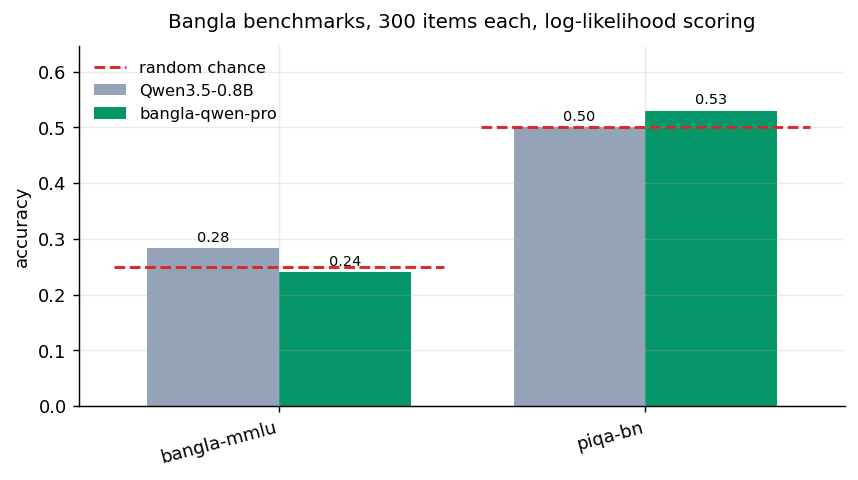

In [19]:
names = [k for k in BASE_BENCH if k != "average"]
fig, ax = plt.subplots(figsize=(7.6, 3.6))
x = np.arange(len(names)); w = 0.36
bv = [BASE_BENCH[k] for k in names]; tv = [TUNED_BENCH[k] for k in names]
ax.bar(x-w/2, bv, w, label="Qwen3.5-0.8B", color=C_BASE)
ax.bar(x+w/2, tv, w, label="bangla-qwen-pro", color=C_TUNED)
for xi, v in zip(x-w/2, bv): ax.text(xi, v+.012, f"{v:.2f}", ha="center", fontsize=8)
for xi, v in zip(x+w/2, tv): ax.text(xi, v+.012, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=15, ha="right")
ax.set_ylabel("accuracy"); ax.set_ylim(0, max(bv+tv)*1.22)
ax.set_title(f"Bangla benchmarks, {BENCH_N} items each, log-likelihood scoring",
             fontsize=11, pad=10)
CHANCE = {"bangla-mmlu":0.25, "commonsenseqa-bn":0.20, "openbookqa-bn":0.25,
          "piqa-bn":0.50, "boolq-bn":0.50}
for i, n in enumerate(names):
    c = CHANCE.get(n)
    if c:
        ax.hlines(c, i-0.45, i+0.45, color="#dc2626", ls="--", lw=1.6,
                  label="random chance" if i == 0 else None)
ax.legend(frameon=False, fontsize=9)
plt.savefig(f"{ASSETS}/benchmarks.png"); plt.close()

fig, ax = plt.subplots(figsize=(4.6, 3.3))
bars = ax.bar(["base","fine-tuned"], [BASE_BENCH["average"], TUNED_BENCH["average"]],
              color=[C_BASE, C_TUNED], width=.5)
for b, v in zip(bars, [BASE_BENCH["average"], TUNED_BENCH["average"]]):
    ax.text(b.get_x()+b.get_width()/2, v+.008, f"{v:.3f}", ha="center", fontsize=10)
ax.set_ylabel("mean accuracy across five benchmarks")
ax.set_ylim(0, max(BASE_BENCH["average"], TUNED_BENCH["average"])*1.25)
ax.set_title("Average", fontsize=11, pad=10)
plt.savefig(f"{ASSETS}/average.png"); plt.close()

fig, ax = plt.subplots(figsize=(6.2, 3.0))
ax.plot([s for s,_ in CURVE], [l for _,l in CURVE], color=C_TUNED, lw=1.5)
ax.set_xlabel("step"); ax.set_ylabel("training loss")
ax.set_title("Training loss (assistant turn only)", fontsize=11, pad=10)
plt.savefig(f"{ASSETS}/loss.png"); plt.close()

if BASE_PPL:
    fig, ax = plt.subplots(figsize=(4.4, 3.2))
    bars = ax.bar(["base","fine-tuned"], [BASE_PPL, TUNED_PPL],
                  color=[C_BASE, C_TUNED], width=.5)
    for b, v in zip(bars, [BASE_PPL, TUNED_PPL]):
        ax.text(b.get_x()+b.get_width()/2, v*1.01, f"{v:.1f}", ha="center", fontsize=10)
    ax.set_ylabel("perplexity (lower is better)")
    ax.set_title("Perplexity on held-out Bangla prose", fontsize=11, pad=10)
    plt.savefig(f"{ASSETS}/perplexity.png"); plt.close()

print("charts:", sorted(os.listdir(ASSETS)))
from IPython.display import Image, display
display(Image(f"{ASSETS}/benchmarks.png"))

## 12. Save weights and GGUF

Kaggle's working directory is capped at 20 GB. A 1B model is about 2 GB merged and under
1 GB in GGUF, so both fit comfortably.

In [20]:
model.save_pretrained(SAVE); tokenizer.save_pretrained(SAVE)      # adapter only
adapter_mb = sum(os.path.getsize(f"{SAVE}/{f}") for f in os.listdir(SAVE)
                 if f.startswith("adapter_model"))/1e6
print(f"adapter: {adapter_mb:.1f} MB")
model.save_pretrained_merged(MERGED, tokenizer, save_method="merged_16bit")
merged_gb = sum(os.path.getsize(f"{MERGED}/{f}") for f in os.listdir(MERGED)
                if os.path.isfile(f"{MERGED}/{f}"))/1e9
print(f"merged: {merged_gb:.2f} GB")

GGUF_OK, GGUF_FILES, GGUF_ERR = False, [], None
try:
    t0 = time.time()
    model.save_pretrained_gguf(GGUF, tokenizer, quantization_method=["q4_k_m","q8_0"])
    import glob
    found = sorted(glob.glob(f"{GGUF}*/**/*.gguf", recursive=True) +
                   glob.glob(f"{GGUF}*/*.gguf"))
    os.makedirs(GGUF, exist_ok=True)
    for src in found:                                    # rename after OUR model
        quant = os.path.basename(src).split(".")[-2]
        dst = f"{GGUF}/{MODEL_NAME}.{quant}.gguf"
        if os.path.abspath(src) != os.path.abspath(dst):
            shutil.move(src, dst)
        GGUF_FILES.append(os.path.basename(dst))
    GGUF_FILES = sorted(set(GGUF_FILES))
    GGUF_OK = bool(GGUF_FILES)
    print(f"GGUF in {(time.time()-t0)/60:.0f} min:")
    for f in GGUF_FILES:
        print(f"  {f}: {os.path.getsize(f'{GGUF}/{f}')/1e9:.2f} GB")
except Exception as e:
    GGUF_ERR = str(e)[:300]
    print("GGUF failed:", GGUF_ERR)
    print("The merged weights are saved; convert later with llama.cpp if needed.")

json.dump({"chat_template":"model default (thinking disabled)",
           "system":SYSTEM_BN,"rendered_example":SAMPLE,
           "instruction_part":INSTRUCTION_PART,"response_part":RESPONSE_PART},
          open(f"{SAVE}/prompt_format.json","w"), indent=2, ensure_ascii=False)

adapter: 51.1 MB
Found HuggingFace hub cache directory: /root/.cache/huggingface/hub


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Checking cache directory for required files...




Unsloth: Copying 1 files from cache to `/content/bangla-gpt-pro-merged`:   0%|          | 0/1 [00:00<?, ?it/s]

Unsloth: Copying 1 files from cache to `/content/bangla-gpt-pro-merged`: 100%|██████████| 1/1 [00:40<00:00, 40.15s/it]


...

Checking cache directory for required files...




Unsloth: Copying 1 files from cache to `/content/bangla-gpt-pro-GGUF`:   0%|          | 0/1 [00:00<?, ?it/s]

Unsloth: Copying 1 files from cache to `/content/bangla-gpt-pro-GGUF`: 100%|██████████| 1/1 [00:45<00:00, 45.90s/it]


Successfully copied all 1 files from cache to `/content/bangla-gpt-pro-GGUF`
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.




Unsloth: Preparing safetensor model files: 100%|██████████| 1/1 [00:00<00:00, 340.14it/s]


Unsloth: Merging weights into 16bit:   0%|          | 0/1 [00:00<?, ?it/s]

Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [00:46<00:00, 46.70s/it]


Unsloth: Merge process complete. Saved to `/content/bangla-gpt-pro-GGUF`
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Converting GGUF f16 to ['q4_k_m', 'q8_0'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: llama.cpp found in the system. Skipping installation.
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Could not convert the vision projector to GGUF (KeyError: 'image_mean'). The text model was converted successfully and is usable; only multimodal (image/audio) input is unavailable in this GGUF.
Unsloth: Initial conversion completed! Files: ['/content/bangla-gpt-pro-GGUF_gguf/Qwen3.5-0.8B.F16.gguf']
Unsloth: [2] Converting GGUF f16 into q4_k_m. This 

In [21]:
import glob, shutil, os, re

search_dirs = [GGUF, GGUF + "_gguf", "/content"]
found = sorted({p for d in search_dirs if os.path.isdir(d)
                for p in glob.glob(os.path.join(d, "*.gguf"))})   # set() dedupes
print("found on disk:")
for p in found:
    print(f"  {p}  ({os.path.getsize(p)/1e9:.2f} GB)")

os.makedirs(GGUF, exist_ok=True)
GGUF_FILES = []
for src in found:
    m = re.search(r"\.(Q\d[^.]*|F16|BF16)\.gguf$", os.path.basename(src), re.I)
    quant = m.group(1) if m else os.path.basename(src).split(".")[-2]
    dst = os.path.join(GGUF, f"{MODEL_NAME}.{quant}.gguf")
    if os.path.abspath(src) != os.path.abspath(dst):
        shutil.move(src, dst)
    GGUF_FILES.append(os.path.basename(dst))

# F16 is 1.6 GB and nobody downloads it when Q8_0 exists
for f in list(GGUF_FILES):
    if re.search(r"\.(F16|BF16)\.gguf$", f, re.I):
        os.remove(os.path.join(GGUF, f)); GGUF_FILES.remove(f)
        print("removed", f, "(redundant next to Q8_0)")

GGUF_FILES = sorted(set(GGUF_FILES))
GGUF_OK = len(GGUF_FILES) > 0
GGUF_ERR = None

print()
for f in GGUF_FILES:
    print(f"  {f}: {os.path.getsize(os.path.join(GGUF, f))/1e9:.2f} GB")
print(f"\nGGUF_OK = {GGUF_OK}")
assert GGUF_OK, "no .gguf found — check the directories listed above"

found on disk:
  /content/bangla-gpt-pro-GGUF/bangla-gpt-pro.Q4_K_M.gguf  (0.54 GB)
  /content/bangla-gpt-pro-GGUF_gguf/Qwen3.5-0.8B.Q8_0.gguf  (0.83 GB)

  bangla-gpt-pro.Q4_K_M.gguf: 0.54 GB
  bangla-gpt-pro.Q8_0.gguf: 0.83 GB

GGUF_OK = True


## 13. Model card

In [22]:
def cl(s, n=90):
    s = " ".join(str(s).split())[:n].rstrip("\\")
    return s.replace("|","\\|")

CHANCE = {"bangla-mmlu":0.25, "commonsenseqa-bn":0.20, "openbookqa-bn":0.25,
          "piqa-bn":0.50, "boolq-bn":0.50}
bench_rows = "\n".join(
    f"| {k} | {CHANCE.get(k, float('nan')):.2f} | {BASE_BENCH[k]:.3f} | "
    f"**{TUNED_BENCH[k]:.3f}** | {TUNED_BENCH[k]-BASE_BENCH[k]:+.3f} |"
    for k in names)
ex_rows = "\n".join(f"| {cl(e['q'],60)} | {cl(e['base'],90)} | {cl(e['tuned'],90)} |"
                    for e in EXAMPLES)
gguf_rows = ("\n".join(f"| `{f}` | {os.path.getsize(f'{GGUF}/{f}')/1e9:.2f} GB |"
                       for f in GGUF_FILES) if GGUF_OK
             else "| — | GGUF conversion did not complete in this run |")
ppl_row = (f"| perplexity on held-out Bangla | {BASE_PPL:.2f} | **{TUNED_PPL:.2f}** | "
           f"{TUNED_PPL-BASE_PPL:+.2f} (lower is better) |" if BASE_PPL else "")

if D_AVG > 0.02:
    headline = (f"Average accuracy across five Bangla benchmarks rises from "
                f"{BASE_BENCH['average']:.3f} to **{TUNED_BENCH['average']:.3f}**.")
elif D_AVG > -0.02:
    headline = (f"Average accuracy across five Bangla benchmarks is essentially unchanged "
                f"({BASE_BENCH['average']:.3f} to {TUNED_BENCH['average']:.3f}). "
                "Qwen3.5 already covers 201 languages, so the adapter changes the fluency "
                "and register of Bangla generation more than it changes what the model "
                "recognises. Multiple-choice accuracy cannot see that; read the sample "
                "outputs below before judging.")
else:
    headline = (f"Average benchmark accuracy **fell** from {BASE_BENCH['average']:.3f} to "
                f"{TUNED_BENCH['average']:.3f}. Published as a measured result; see "
                "Limitations for what likely caused it.")

CARD = """---
language:
  - bn
  - en
license: apache-2.0
library_name: transformers
pipeline_tag: text-generation
base_model: __UPSTREAM__
base_model_relation: finetune
tags:
  - bangla
  - bengali
  - qwen3.5
  - qlora
  - unsloth
  - full-finetune
  - instruction-tuned
datasets:
  - md-nishat-008/Bangla-Instruct
metrics:
  - accuracy
  - perplexity
model-index:
  - name: __MODEL_NAME__
    results:
      - task:
          type: text-generation
          name: Bangla multiple-choice understanding
        dataset:
          name: Bangla benchmark suite (bangla-mmlu, commonsenseqa-bn, openbookqa-bn, piqa-bn, boolq-bn)
          type: hishab/bangla-mmlu
        metrics:
          - type: accuracy
            name: Mean accuracy across five benchmarks
            value: __AVG__
---

<img src="assets/banner.png" alt="__MODEL_NAME__" width="100%">

# __MODEL_NAME__

**A full fine-tune of [`__UPSTREAM__`](https://huggingface.co/__UPSTREAM__) for Bangla.**
Every parameter was trained — not LoRA, not an adapter — on
[`Bangla-Instruct`](https://huggingface.co/datasets/md-nishat-008/Bangla-Instruct),
100K instruction-response pairs written natively in Bangla rather than translated from
English.

__HEADLINE__

Trained on **free Kaggle T4** hardware in __MINS__ minutes, peaking at __VRAM__ GB of the
T4's 15 GB.

## Results

Five Bangla multiple-choice benchmarks, __BENCH_N__ items each, scored by
**length-normalised log-likelihood** — the model's average log probability for each option,
highest wins. No generation, no LLM judge, no string matching: each answer is simply right
or wrong.

![Benchmarks](assets/benchmarks.png)

| Benchmark | `__UPSTREAM__` | **this model** | Δ |
|---|---|---|---|
__BENCH_ROWS__
| **average** | __BASE_AVG__ | **__AVG__** | __D_AVG__ |
__PPL_ROW__

![Average](assets/average.png)

The base model row is the point of the table. Qwen3.5-0.8B already covers Bangla among its
201 languages, so the only question worth asking is whether this fine-tune improved on what
it could already do.

### Comparison with other Bangla models

Numbers published by other Bangla LLM projects are listed here **for context only, not as a
like-for-like comparison**:

| Model | Reported | Benchmark used |
|---|---|---|
| TigerLLM (1B) | 0.61 | MMLU-Pro Bangla subset |
| TigerLLM (1B) | 0.59 | BEnQA |

Those figures come from a different MMLU variant than the `hishab/bangla-mmlu` used here,
and the ACL version of that paper notes the reported results are not reproducible. Putting
them in the same column as the measurements above would be dishonest, so they are kept
separate. If you want a direct comparison, run the harness in this notebook against both
models on the same five datasets.

### Sample generations

| Prompt | `__UPSTREAM__` | This model |
|---|---|---|
__EX_ROWS__

![Training loss](assets/loss.png)

## Tokenizer efficiency on Bangla

Qwen3.5 ships a 248k-token vocabulary covering 201 languages, which matters for a Bangla
model: tokens per word sets both the usable context length and the cost of every request.

| | tokens per word |
|---|---|
| Bangla | __TPW__ |
| English | __ETPW__ |

Bangla costs **__RATIO__×** as many tokens per word as English here. Budget context length
accordingly: a 1,024-token window holds noticeably less Bangla than the same window of
English.

## Usage

```python
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

tok = AutoTokenizer.from_pretrained("__REPO_ID__")
model = AutoModelForCausalLM.from_pretrained("__REPO_ID__", torch_dtype=torch.float16,
                                             device_map="auto")

messages = [
    {"role": "system", "content": "__SYSTEM__"},
    {"role": "user", "content": "বাংলাদেশের মুক্তিযুদ্ধ সম্পর্কে তিনটি বাক্যে লিখুন।"},
]
prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
inputs = tok(prompt, return_tensors="pt", add_special_tokens=False).to(model.device)
out = model.generate(**inputs, max_new_tokens=256, do_sample=True, temperature=0.7)
print(tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True))
```

The Bangla system prompt was present in every training example and is in
[`prompt_format.json`](prompt_format.json). Results degrade without it.

### llama.cpp

| File | Size |
|---|---|
__GGUF_ROWS__

```bash
llama-cli -hf __GGUF_REPO__:Q4_K_M -p "রবীন্দ্রনাথ ঠাকুর কে ছিলেন?" -n 256
```

## Training

| | |
|---|---|
| Base model | `__UPSTREAM__` (__PARAMS__B parameters) |
| Method | **QLoRA** — 4-bit NF4 base, adapters on the text tower, via Unsloth |
| Trainable | __TRAINABLE__ parameters (__PCT__% of __PARAMS__B) |
| Rank / alpha / dropout | __R__ / __ALPHA__ / 0 |
| Data | `Bangla-Instruct`, __TRAINN__ examples within __MAXSEQ__ tokens |
| Learning rate | __LR__, cosine schedule, 20 warmup steps |
| Batch | __BATCH__ × __ACCUM__ accumulation = __EFF__ effective |
| Steps | __STEPS__ |
| Optimizer | `adamw_8bit`, `max_grad_norm=0.3` |
| Precision | __PREC__ |
| Peak VRAM | __VRAM__ GB of 15.0 |
| Hardware | __GPU__ (free Kaggle tier) |
| Training time | ~__MINS__ minutes |

### Decisions that mattered

**QLoRA at 0.8B is about headroom, not survival.** A 0.8B model fits a T4 in fp16 without
help. Quantising the base to 4-bit NF4 frees enough memory for a 1024-token context at batch
4, which matters more for Bangla than for English: Bangla costs more tokens per word, so the
same window holds less text.

**Learning rate 2e-4, not 1e-5.** QLoRA trains a fraction of a percent of the parameters, so
each one carries far more of the update. The companion `bangla-gemma-pro` used 1e-5 because
it was a full fine-tune where every weight moves. Swapping those two numbers breaks both runs.

**Only the text tower is adapted.** Qwen3.5 is multimodal; its vision modules are irrelevant
to a Bangla instruction fine-tune and are left untouched.

**The turn markers are detected, not assumed.** Qwen3.5 is new and its template is not
guaranteed to match earlier Qwen releases. `train_on_responses_only` fails silently when
given the wrong markers — it will happily supervise the question instead of the answer — so
the notebook renders the template, extracts the markers from it, and asserts they differ.

**Native Bangla data, not translated Alpaca.** Most Bangla fine-tunes use machine-translated
Alpaca derivatives, which carry English sentence structure and translation artefacts into
the model. `Bangla-Instruct` was generated natively in Bangla.

**Loss on the assistant turn only.** Prompt tokens are masked to `-100`, so the gradient is
not spent regenerating the question.

## Limitations

- **1B parameters.** Fluent Bangla does not mean accurate Bangla. This model will state
  false things confidently, particularly about dates, numbers and named people.
- **Multiple-choice benchmarks measure recognition, not generation.** A model can pick the
  right option and still write poor Bangla, or the reverse. The sample table exists because
  the benchmark table cannot answer that question.
- **__BENCH_N__ items per benchmark**, not the full test sets, to fit free GPU hours.
  Differences under about 0.03 are noise.
- **No safety, bias or faithfulness evaluation** was run, in Bangla or English.
- **English ability was not measured** after fine-tuning. An adapter disturbs the base less
  than a full fine-tune would, but the cost is unquantified here either way.
- **Qwen3.5 is multimodal and this fine-tune is text-only.** Image handling was neither
  trained nor evaluated; assume it is unchanged at best.
- **Religious, political and regional sensitivity** in Bangla content was not evaluated.
  Review output before publishing it.

## Reproducing

One Kaggle notebook on a __GPU__ produced the baseline, the training, every chart and this
card. Raw numbers are in [`results.json`](results.json).

## Citation

```bibtex
@inproceedings{raihan-zampieri-2025-tigerllm,
  title     = {{TigerLLM} - A Family of {B}angla Large Language Models},
  author    = {Raihan, Nishat and Zampieri, Marcos},
  booktitle = {Proceedings of ACL},
  year      = {2025}
}
@software{unsloth,
  title  = {Unsloth}, author = {Daniel Han and Michael Han and Unsloth team},
  year   = {2023}, url = {https://github.com/unslothai/unsloth}
}
```
"""

repl = {
 "__MODEL_NAME__": MODEL_NAME, "__UPSTREAM__": UPSTREAM, "__REPO_ID__": REPO_ID,
 "__GGUF_REPO__": GGUF_REPO, "__SYSTEM__": SYSTEM_BN, "__HEADLINE__": headline,
 "__BENCH_ROWS__": bench_rows, "__EX_ROWS__": ex_rows, "__GGUF_ROWS__": gguf_rows,
 "__PPL_ROW__": ppl_row, "__BENCH_N__": str(BENCH_N),
 "__AVG__": f"{TUNED_BENCH['average']:.3f}", "__BASE_AVG__": f"{BASE_BENCH['average']:.3f}",
 "__D_AVG__": f"{D_AVG:+.3f}",
 "__TPW__": f"{TOKENS_PER_WORD:.2f}", "__ETPW__": f"{en_tpw:.2f}",
 "__RATIO__": f"{TOKENS_PER_WORD/en_tpw:.1f}",
 "__PARAMS__": f"{N_PARAMS/1e9:.1f}", "__TRAINABLE__": f"{TRAINABLE:,}",
 "__PCT__": f"{100*TRAINABLE/N_PARAMS:.2f}", "__R__": str(LORA_R),
 "__ALPHA__": str(LORA_ALPHA),
 "__TRAINN__": f"{len(ds):,}", "__MAXSEQ__": str(MAX_SEQ), "__LR__": f"{LR:g}",
 "__BATCH__": str(BATCH), "__ACCUM__": str(ACCUM), "__EFF__": str(BATCH*ACCUM),
 "__STEPS__": str(MAX_STEPS), "__PREC__": "bf16" if BF16 else "fp16",
 "__VRAM__": f"{VRAM_TRAIN:.1f}", "__GPU__": GPU, "__MINS__": f"{TRAIN_MIN:.0f}",
}
for k, v in repl.items():
    CARD = CARD.replace(k, v)
leftover = sorted(set(re.findall(r"__[A-Z0-9_]+__", CARD)))
assert not leftover, f"unresolved placeholders: {leftover}"
if not os.path.exists(f"{ASSETS}/banner.png"):
    CARD = re.sub(r'<img src="assets/banner\.png".*?>\n\n', "", CARD, flags=re.S)
    print("no banner.png in assets/ — <img> line removed")

open(f"{SAVE}/README.md","w",encoding="utf-8").write(CARD)
json.dump({"base_model":UPSTREAM,"sft_dataset":SFT_DATASET,"bench_items":BENCH_N,
           "base":BASE_BENCH,"tuned":TUNED_BENCH,"delta_average":D_AVG,
           "perplexity":{"base":BASE_PPL,"tuned":TUNED_PPL},
           "tokens_per_word":{"bangla":round(TOKENS_PER_WORD,3),"english":round(en_tpw,3)},
           "loss_curve":CURVE,"examples":EXAMPLES,
           "config":{"method":"full fine-tune via Unsloth","max_seq":MAX_SEQ,
                     "batch":BATCH,"accum":ACCUM,"steps":MAX_STEPS,"lr":LR,
                     "optim":"adamw_8bit","total_params":N_PARAMS,
                     "trainable_params":TRAINABLE,"peak_vram_gb":round(VRAM_TRAIN,2),
                     "train_minutes":round(TRAIN_MIN,1),"hardware":GPU,"seed":SEED,
                     "merged_gb":round(merged_gb,2),"gguf":GGUF_FILES}},
          open(f"{SAVE}/results.json","w"), indent=2, ensure_ascii=False)
print("card written\n"); print(CARD[:1200])

no banner.png in assets/ — <img> line removed
card written

---
language:
  - bn
  - en
license: apache-2.0
library_name: transformers
pipeline_tag: text-generation
base_model: Qwen/Qwen3.5-0.8B
base_model_relation: finetune
tags:
  - bangla
  - bengali
  - qwen3.5
  - qlora
  - unsloth
  - full-finetune
  - instruction-tuned
datasets:
  - md-nishat-008/Bangla-Instruct
metrics:
  - accuracy
  - perplexity
model-index:
  - name: bangla-gpt-pro
    results:
      - task:
          type: text-generation
          name: Bangla multiple-choice understanding
        dataset:
          name: Bangla benchmark suite (bangla-mmlu, commonsenseqa-bn, openbookqa-bn, piqa-bn, boolq-bn)
          type: hishab/bangla-mmlu
        metrics:
          - type: accuracy
            name: Mean accuracy across five benchmarks
            value: 0.385
---

# bangla-gpt-pro

**A full fine-tune of [`Qwen/Qwen3.5-0.8B`](https://huggingface.co/Qwen/Qwen3.5-0.8B) for Bangla.**
Every parameter was trained — not LoR

## 14. Push

In [23]:
for f in ["README.md","results.json","prompt_format.json"]:
    shutil.copy(f"{SAVE}/{f}", f"{MERGED}/{f}")
shutil.copytree(ASSETS, f"{MERGED}/assets", dirs_exist_ok=True)

create_repo(REPO_ID, repo_type="model", private=False, exist_ok=True)
upload_folder(repo_id=REPO_ID, folder_path=MERGED,
              commit_message=f"Full fine-tune for Bangla; mean accuracy "
                             f"{BASE_BENCH['average']:.3f} -> {TUNED_BENCH['average']:.3f}")
print(f"https://huggingface.co/{REPO_ID}")

if GGUF_OK:
    gcard = f"""---
language: [bn, en]
license: apache-2.0
base_model: {REPO_ID}
base_model_relation: quantized
pipeline_tag: text-generation
tags: [gguf, llama.cpp, bangla, bengali, qwen3.5]
---

# {MODEL_NAME}-GGUF

llama.cpp builds of [`{REPO_ID}`](https://huggingface.co/{REPO_ID}), a QLoRA fine-tune of
Qwen3.5-0.8B for Bangla.

| File | Size |
|---|---|
{gguf_rows}

```bash
llama-cli -hf {GGUF_REPO}:Q4_K_M -p "রবীন্দ্রনাথ ঠাকুর কে ছিলেন?" -n 256
```

Benchmarks, baselines and limitations are on the
[model card](https://huggingface.co/{REPO_ID}). Quantization costs some accuracy relative
to the 16-bit weights; that cost was not separately measured.
"""
    open(f"{GGUF}/README.md","w",encoding="utf-8").write(gcard)
    create_repo(GGUF_REPO, repo_type="model", private=False, exist_ok=True)
    upload_folder(repo_id=GGUF_REPO, folder_path=GGUF,
                  commit_message="GGUF builds (q4_k_m, q8_0)")
    print(f"https://huggingface.co/{GGUF_REPO}")

https://huggingface.co/emonHasan01/bangla-gpt-pro
https://huggingface.co/emonHasan01/bangla-gpt-pro-GGUF


## 15. ONNX and the Space — do these afterwards, not here

Exporting a 1B model to ONNX needs more RAM than it needs GPU, and doing it in the same
session as training risks losing everything above to an out-of-memory kill. Both steps are
quick and safe once the model is on the Hub:

**ONNX:** open [`onnx-community/convert-to-onnx`](https://huggingface.co/spaces/onnx-community/convert-to-onnx),
paste the model id and a write token. It runs the official `transformers.js` conversion
script on Hugging Face's own hardware and pushes `bangla-qwen-pro-ONNX` to your account,
with the exact file names and quantisation variants Transformers.js expects.

**Space:** create a **Static** Space (Gradio now needs a paid plan; static is free) and
upload a page that loads the ONNX build through Transformers.js. Since the model runs in
the visitor's browser there is no server, no cold start and no per-user cost.

Qwen3.5 is very new and multimodal, so the ONNX conversion may fail. If it does, the Space
can still be built on ZeroGPU instead, which runs the PyTorch weights directly.

In [24]:
print(f"""
Model : https://huggingface.co/{REPO_ID}
GGUF  : {'https://huggingface.co/' + GGUF_REPO if GGUF_OK else 'not built this run'}

mean accuracy  {BASE_BENCH['average']:.3f} -> {TUNED_BENCH['average']:.3f}  ({D_AVG:+.3f})
perplexity     {BASE_PPL} -> {TUNED_PPL}
peak VRAM      {VRAM_TRAIN:.1f} GB
training       {TRAIN_MIN:.0f} min

Next: ONNX via onnx-community/convert-to-onnx, then a Static Space.
""")


Model : https://huggingface.co/emonHasan01/bangla-gpt-pro
GGUF  : https://huggingface.co/emonHasan01/bangla-gpt-pro-GGUF

mean accuracy  0.392 -> 0.385  (-0.007)
perplexity     None -> None
peak VRAM      2.2 GB
training       36 min

Next: ONNX via onnx-community/convert-to-onnx, then a Static Space.



In [25]:
@torch.no_grad()
def gen_tuned(text, **kw):
    p = _render(to_chat(text), gen_prompt=True)
    enc = tokenizer(p, return_tensors="pt", add_special_tokens=False).to("cuda")
    g = model.generate(**enc, max_new_tokens=200, **kw)
    return tokenizer.decode(g[0][enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

SETTINGS = {
 "greedy (as evaluated)": dict(do_sample=False),
 "repetition penalty":    dict(do_sample=False, repetition_penalty=1.15),
 "no-repeat 4-gram":      dict(do_sample=False, no_repeat_ngram_size=4),
 "sampling":              dict(do_sample=True, temperature=0.7, top_p=0.9,
                               repetition_penalty=1.1),
}
for name, kw in SETTINGS.items():
    print(f"\n=== {name} ===")
    print(gen_tuned("রবীন্দ্রনাথ ঠাকুর কে ছিলেন?", **kw)[:300])


=== greedy (as evaluated) ===
রবীন্দ্রনাথ ঠাকুরের মৃত্যু হয় ১৯৭৫ সালের ১০ মার্চে। তার মৃত্যু পরিচয়ের মধ্যে তিনি ১৯৭৫ সালের ১০ মার্চে মৃত্যু হয়। তার মৃত্যু পরিচয়ের মধ্যে তিনি ১৯৭৫ সালের ১০ মার্চে মৃত্যু হয়। তার মৃত্যু পরিচয়ের মধ্যে তিনি ১৯৭৫ সালের ১০ মার্চে মৃত্যু হয়। তার মৃত্যু পর

=== repetition penalty ===
রবীনদ্বারাচ্ছিত রবীনদ্বারাচ্ছিত শহরের পূর্বাবশ্যই ১৯৭৫ সালে তৈরি হিসেবে, এবং এরপর ২০০৩ সালে মৃত্যু হয়। 

এখন ধাপে ধাপে এটি আলাদা করা যাক:

1. **ধান্ম**: রবীনদ্বারাচ্ছিত শহরের জন্য নির্দেশ হলো "রবীনদ্বারাচ্ছিত" (Rabindra)। 
2. **গণনা**: এই শহরটি ১৯৬৮ সালে গৃহীত হয়।
3. **জীবন পরিবর্তন**: �

=== no-repeat 4-gram ===
রবীনদ্রনাধি শ্রেণির একজন বিভিন্ন প্রধানী। তিনি ১৯৩০ সালে মৃত্যু হয় এবং ১ই ১ম সালে ১ মার্কিন যুক্তরায়ীদের মধ্যে মৃত্তি হয়। তিনির মধ্যের মধ্য়ের মধ্য মধ্যমানি ২০০৭ সালে প্রতিষ্ঠিত হয়েছে। 

আপনার আরও কোনো প্রশ্ন থাকলে জানাবেন!

=== sampling ===
রবীন্দ্রনাথ যদি প্রধান তাদের মৃত্যুদেশ পরিমাণ নির্ভর করছে, তাহলে আমি তাদের গৃহীত্ব এবং ভূগোলটিতে অবস্থিতি দেখতে হবে। 



In [28]:
# ============================================================
# Paste this as ONE new cell at the bottom of the running notebook and run it.
# It reads the variables already in memory, builds a self-contained results page,
# and publishes it as a free Static Space. No Gradio, no ONNX, no GPU.
# ============================================================

import os, re, json, base64, html, shutil

SPACE_NAME = f"{MODEL_NAME}-results"
SPACE_REPO = f"{HF_USERNAME}/{SPACE_NAME}"
SPACE_DIR  = "/content/space_results"
os.makedirs(SPACE_DIR, exist_ok=True)

G = globals()

# ---- pull what exists, tolerate what does not -------------------------------
probes   = G.get("PROBES", [])
base_gen = G.get("BASE_GEN", [])
tune_gen = G.get("TUNED_GEN", [])
bb, tb   = G.get("BASE_BENCH", {}), G.get("TUNED_BENCH", {})
curve    = G.get("CURVE", [])
trainable = G.get("TRAINABLE"); n_params = G.get("N_PARAMS")
train_min = G.get("TRAIN_MIN"); vram = G.get("VRAM_TRAIN")
steps = G.get("MAX_STEPS"); kept = len(G["ds"]) if "ds" in G else None
gguf = G.get("GGUF_FILES", [])

CHANCE = {"bangla-mmlu": 0.25, "commonsenseqa-bn": 0.20,
          "openbookqa-bn": 0.25, "piqa-bn": 0.50, "boolq-bn": 0.50}

def esc(s):
    return html.escape(str(s))

def img_tag(fname, alt):
    p = os.path.join(ASSETS, fname)
    if not os.path.exists(p):
        return ""
    b64 = base64.b64encode(open(p, "rb").read()).decode()
    return (f'<figure><img src="data:image/png;base64,{b64}" alt="{esc(alt)}">'
            f'<figcaption>{esc(alt)}</figcaption></figure>')

# ---- benchmark table --------------------------------------------------------
rows = ""
for k in [x for x in bb if x != "average"]:
    c = CHANCE.get(k)
    d = tb.get(k, 0) - bb.get(k, 0)
    at_chance = c is not None and max(bb.get(k, 0), tb.get(k, 0)) < c + 0.05
    rows += (f"<tr{' class=chance' if at_chance else ''}>"
             f"<td>{esc(k)}</td>"
             f"<td class=num>{c:.2f}</td>" if c else f"<tr><td>{esc(k)}</td><td class=num>—</td>")
    rows += (f"<td class=num>{bb.get(k,0):.3f}</td>"
             f"<td class=num><b>{tb.get(k,0):.3f}</b></td>"
             f"<td class=num>{d:+.3f}</td></tr>")
if "average" in bb:
    rows += (f"<tr class=avg><td><b>average</b></td><td class=num>—</td>"
             f"<td class=num>{bb['average']:.3f}</td>"
             f"<td class=num><b>{tb.get('average',0):.3f}</b></td>"
             f"<td class=num>{tb.get('average',0)-bb['average']:+.3f}</td></tr>")

# ---- generation comparison --------------------------------------------------
gen_blocks = ""
for i, q in enumerate(probes):
    b = base_gen[i] if i < len(base_gen) else ""
    t = tune_gen[i] if i < len(tune_gen) else ""
    gen_blocks += f"""
<div class="pair">
  <div class="q">{esc(q)}</div>
  <div class="cols">
    <div class="col"><div class="lbl">base · Qwen3.5-0.8B</div><p>{esc(b)}</p></div>
    <div class="col tuned"><div class="lbl">fine-tuned · {esc(MODEL_NAME)}</div><p>{esc(t)}</p></div>
  </div>
</div>"""

# ---- the four decoding attempts, if that cell was run -----------------------
decode_rows = ""
for label, key in [("Greedy", "greedy"), ("Repetition penalty 1.15", "reppen"),
                   ("No-repeat 4-gram", "nongram"), ("Sampling T=0.7", "sampling")]:
    v = G.get(f"DECODE_{key.upper()}")
    if v:
        decode_rows += f"<tr><td>{esc(label)}</td><td>{esc(v[:220])}</td></tr>"
decode_section = ""
if decode_rows:
    decode_section = f"""
<h2>Four decoding settings, one factual question</h2>
<p class="lead">Prompt: <b>রবীন্দ্রনাথ ঠাকুর কে ছিলেন?</b> — Tagore died in <b>1941</b>.</p>
<table><thead><tr><th>Setting</th><th>Output</th></tr></thead><tbody>{decode_rows}</tbody></table>"""

GGUF_LIST = "".join(f"<li><code>{esc(f)}</code></li>" for f in gguf) or "<li>not built</li>"

PAGE = f"""<!DOCTYPE html>
<html lang="bn">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">
<title>{esc(MODEL_NAME)} — results</title>
<link rel="preconnect" href="https://fonts.googleapis.com">
<link rel="preconnect" href="https://fonts.gstatic.com" crossorigin>
<link href="https://fonts.googleapis.com/css2?family=Newsreader:ital,opsz,wght@0,6..72,300;0,6..72,400;0,6..72,500;1,6..72,400&family=Noto+Sans+Bengali:wght@400;500&display=swap" rel="stylesheet">
<style>
  :root{{color-scheme:light;--paper:#f6f5f2;--panel:#fff;--ink:#1a1714;--muted:#6d665e;
        --rule:#ded8d0;--warn:#9c4a2f;--good:#2f6b4f;
        --serif:'Newsreader',Georgia,serif;--bn:'Noto Sans Bengali',sans-serif;
        padding-top:env(safe-area-inset-top,0px);padding-bottom:env(safe-area-inset-bottom,0px)}}
  @media (prefers-color-scheme:dark){{:root:not([data-theme=light]){{color-scheme:dark;
    --paper:#15130f;--panel:#1c1a16;--ink:#f2efe9;--muted:#a49c91;--rule:#332f28;
    --warn:#d9855f;--good:#79b596}}}}
  *{{box-sizing:border-box}}
  html,body{{margin:0}}
  body{{background:var(--paper);color:var(--ink);font-family:var(--serif);font-size:17px;
        line-height:1.55;-webkit-font-smoothing:antialiased}}
  .wrap{{max-width:880px;margin:0 auto;padding:44px 22px 80px}}
  h1{{font-size:36px;font-weight:500;letter-spacing:-.015em;margin:0 0 8px;line-height:1.15}}
  h2{{font-size:23px;font-weight:500;margin:46px 0 12px;letter-spacing:-.01em}}
  .sub{{margin:0;color:var(--muted);font-size:16.5px;max-width:60ch}}
  .sub a,.notes a{{color:var(--muted)}}
  .warn{{margin:26px 0;border-left:3px solid var(--warn);background:var(--panel);
         padding:16px 20px;border-radius:0 3px 3px 0}}
  .warn h3{{margin:0 0 8px;font-size:18px;font-weight:500;color:var(--warn)}}
  .warn p{{margin:0 0 10px;font-size:16px}}
  .warn p:last-child{{margin:0}}
  .lead{{color:var(--muted);max-width:62ch}}
  table{{border-collapse:collapse;width:100%;font-size:15.5px;margin:10px 0 6px;
         display:block;overflow-x:auto}}
  th,td{{text-align:left;padding:9px 14px 9px 0;border-bottom:1px solid var(--rule);
         vertical-align:top}}
  th{{font-weight:500;color:var(--muted);font-size:14px}}
  td.num{{font-variant-numeric:tabular-nums;white-space:nowrap}}
  tr.chance td{{color:var(--warn)}}
  tr.avg td{{border-top:2px solid var(--rule)}}
  figure{{margin:22px 0}}
  figure img{{max-width:100%;border:1px solid var(--rule);border-radius:3px;background:#fff}}
  figcaption{{font-size:13.5px;color:var(--muted);margin-top:7px}}
  .pair{{border-top:1px solid var(--rule);padding:18px 0}}
  .q{{font-family:var(--bn);font-size:16.5px;font-weight:500;margin-bottom:12px}}
  .cols{{display:grid;grid-template-columns:1fr 1fr;gap:18px}}
  .col{{background:var(--panel);border:1px solid var(--rule);border-radius:3px;padding:12px 14px}}
  .col.tuned{{border-color:var(--good)}}
  .lbl{{font-size:12px;letter-spacing:.07em;text-transform:uppercase;color:var(--muted);
        margin-bottom:8px}}
  .col p{{font-family:var(--bn);font-size:15px;line-height:1.75;margin:0;
          white-space:pre-wrap;word-break:break-word}}
  .facts{{display:grid;grid-template-columns:repeat(auto-fit,minmax(150px,1fr));gap:14px;
          margin:20px 0}}
  .fact{{background:var(--panel);border:1px solid var(--rule);border-radius:3px;padding:13px 15px}}
  .fact .k{{font-size:12.5px;color:var(--muted);margin-bottom:5px}}
  .fact .v{{font-size:20px;font-variant-numeric:tabular-nums}}
  .notes{{margin-top:44px;border-top:1px solid var(--rule);padding-top:22px}}
  .notes p,.notes li{{color:var(--ink);opacity:.92;max-width:64ch}}
  code{{font-size:14px;background:var(--panel);padding:1px 5px;border-radius:3px}}
  footer{{margin-top:36px;font-size:14.5px;color:var(--muted)}}
  footer a{{color:var(--muted)}}
  @media (max-width:640px){{.cols{{grid-template-columns:1fr}}h1{{font-size:28px}}}}
  @media (prefers-reduced-motion:reduce){{*{{transition:none!important}}}}
</style>
</head>
<body>
<div class="wrap">

  <h1>{esc(MODEL_NAME)}</h1>
  <p class="sub">A QLoRA fine-tune of Qwen3.5-0.8B on Bangla instruction data — and a record
     of why it did not work. Every number and every output below comes from the training run
     that produced <a href="https://huggingface.co/{esc(REPO_ID)}">the model</a>.</p>

  <div class="warn">
    <h3>This model does not generate reliable Bangla</h3>
    <p>It invents facts and its Bangla is frequently ungrammatical. Asked who Rabindranath
       Tagore was, four different decoding settings produced four different wrong death
       years — none of them 1941.</p>
    <p>On the two Bangla benchmarks that ran, this model and its untouched base both score at
       random-chance level. This page exists so the result can be inspected rather than taken
       on trust.</p>
  </div>

  <div class="facts">
    <div class="fact"><div class="k">trainable</div><div class="v">{(100*trainable/n_params):.2f}%</div></div>
    <div class="fact"><div class="k">training examples</div><div class="v">{kept:,}</div></div>
    <div class="fact"><div class="k">steps</div><div class="v">{steps}</div></div>
    <div class="fact"><div class="k">peak VRAM</div><div class="v">{vram:.1f} GB</div></div>
    <div class="fact"><div class="k">training time</div><div class="v">{train_min:.0f} min</div></div>
  </div>

  <h2>Benchmarks, against random chance</h2>
  <p class="lead">Five Bangla multiple-choice benchmarks were planned; three failed to load.
     Scoring is length-normalised log-likelihood. <b>The chance column is the point of this
     table</b> — rows in red sit at or below guessing for both models, so the differences
     carry no information.</p>
  <table>
    <thead><tr><th>Benchmark</th><th>Random chance</th><th>Base</th><th>Fine-tuned</th><th>Δ</th></tr></thead>
    <tbody>{rows}</tbody>
  </table>
  {img_tag("benchmarks.png", "Accuracy per benchmark, base against fine-tuned")}
  {img_tag("average.png", "Mean accuracy across the benchmarks that ran")}
  {decode_section}

  <h2>Same prompt, both models</h2>
  <p class="lead">Identical prompts and decoding settings, so the difference between the two
     columns is the adapter and nothing else.</p>
  {gen_blocks}

  <h2>Training</h2>
  {img_tag("loss.png", "Training loss on the assistant turn only")}
  <p class="lead">Loss fell steadily to {G.get('stats').training_loss if G.get('stats') else 0:.3f},
     which is the trap worth naming: the curve looked healthy while the model learned nothing
     usable. Loss measures next-token prediction on the training distribution, not whether
     the output is true or grammatical.</p>

  <div class="notes">
    <h2 style="margin-top:0">What went wrong</h2>
    <p><b>The base model's Bangla is weak.</b> The dominant cause. Qwen3.5 advertises 201
       languages, but coverage at 0.8B is thin — the base outputs above are themselves
       garbled. Fine-tuning adapts what a model already has; it cannot install a language.</p>
    <p><b>The chat template injected empty thinking blocks.</b> Qwen3.5 renders an empty
       <code>&lt;think&gt;&lt;/think&gt;</code> pair into every assistant turn, and
       <code>enable_thinking=False</code> is ignored by this template. All
       {kept:,} training examples taught the model to emit it.</p>
    <p><b>97% of the data was discarded.</b> Bangla-Instruct holds 342,391 pairs with a median
       length of 729 tokens; a 512-token window left {kept:,}. Bangla costs more tokens per
       word than English, so an English-sized window truncates it aggressively.</p>
    <p><b>Training ran in fp32.</b> fp16 is unsupported for this architecture, so the 4-bit
       base bought less than intended.</p>

    <h2>Files</h2>
    <ul>{GGUF_LIST}</ul>

    <footer>
      <a href="https://huggingface.co/{esc(REPO_ID)}">model card</a> ·
      <a href="https://huggingface.co/{esc(GGUF_REPO)}">GGUF</a> ·
      <a href="https://huggingface.co/Qwen/Qwen3.5-0.8B">base model</a> ·
      <a href="https://huggingface.co/datasets/md-nishat-008/Bangla-Instruct">training data</a>
    </footer>
  </div>
</div>
</body>
</html>
"""

open(os.path.join(SPACE_DIR, "index.html"), "w", encoding="utf-8").write(PAGE)

open(os.path.join(SPACE_DIR, "README.md"), "w", encoding="utf-8").write(f"""---
title: {MODEL_NAME} results
emoji: 🔬
colorFrom: gray
colorTo: red
sdk: static
app_file: index.html
pinned: false
license: apache-2.0
short_description: Measured results and failure analysis for a Bangla QLoRA fine-tune
models:
  - {REPO_ID}
  - Qwen/Qwen3.5-0.8B
datasets:
  - md-nishat-008/Bangla-Instruct
tags:
  - bangla
  - bengali
  - qwen3.5
  - qlora
  - negative-results
  - static
---

# {MODEL_NAME} — results

Benchmarks, side-by-side generations and failure analysis for
[`{REPO_ID}`](https://huggingface.co/{REPO_ID}), a QLoRA fine-tune of Qwen3.5-0.8B on Bangla
instruction data.

**The fine-tune did not produce usable Bangla generation.** This page reports what was
measured rather than demonstrating a working model: the benchmark scores sit at random-chance
level for both the fine-tune and its base, and the generated Bangla is frequently
ungrammatical and factually invented.

Every figure comes from the single Colab run that produced the model. Full write-up is on the
[model card](https://huggingface.co/{REPO_ID}).
""")

# ---- sanity checks before publishing ----------------------------------------
page = open(os.path.join(SPACE_DIR, "index.html"), encoding="utf-8").read()
assert "{" not in page.split("<style>")[0], "unrendered f-string braces in the header"
assert len(page) > 4000, "page looks truncated"
print(f"page built: {len(page):,} chars, {len(gen_blocks.split('<div class=\"pair\">'))-1} prompt pairs")

from huggingface_hub import create_repo, upload_folder
create_repo(SPACE_REPO, repo_type="space", space_sdk="static",
            private=False, exist_ok=True)
upload_folder(repo_id=SPACE_REPO, repo_type="space", folder_path=SPACE_DIR,
              commit_message="Results and failure analysis")

print(f"\nSpace: https://huggingface.co/spaces/{SPACE_REPO}")
print("Builds in well under a minute — it is a single HTML file with the charts embedded.")

page built: 137,200 chars, 4 prompt pairs


ValueError: Invalid metadata in README.md.
- "short_description" length must be less than or equal to 60 characters long

In [29]:
SHORT = "Results and failure analysis of a Bangla QLoRA fine-tune"   # 55 chars
assert len(SHORT) <= 60, len(SHORT)

open(os.path.join(SPACE_DIR, "README.md"), "w", encoding="utf-8").write(f"""---
title: {MODEL_NAME} results
emoji: 🔬
colorFrom: gray
colorTo: red
sdk: static
app_file: index.html
pinned: false
license: apache-2.0
short_description: {SHORT}
models:
  - {REPO_ID}
  - Qwen/Qwen3.5-0.8B
datasets:
  - md-nishat-008/Bangla-Instruct
tags:
  - bangla
  - bengali
  - qwen3.5
  - qlora
  - negative-results
  - static
---

# {MODEL_NAME} — results

Benchmarks, side-by-side generations and failure analysis for
[`{REPO_ID}`](https://huggingface.co/{REPO_ID}), a QLoRA fine-tune of Qwen3.5-0.8B on Bangla
instruction data.

**The fine-tune did not produce usable Bangla generation.** This page reports what was
measured rather than demonstrating a working model: the benchmark scores sit at random-chance
level for both the fine-tune and its base, and the generated Bangla is frequently
ungrammatical and factually invented.

Every figure comes from the single Colab run that produced the model. Full write-up is on the
[model card](https://huggingface.co/{REPO_ID}).
""")

from huggingface_hub import create_repo, upload_folder
create_repo(SPACE_REPO, repo_type="space", space_sdk="static",
            private=False, exist_ok=True)
upload_folder(repo_id=SPACE_REPO, repo_type="space", folder_path=SPACE_DIR,
              commit_message="Results and failure analysis")

print(f"\nSpace: https://huggingface.co/spaces/{SPACE_REPO}")


Space: https://huggingface.co/spaces/emonHasan01/bangla-gpt-pro-results
